In [55]:
import duckdb
import pandas as pd

database_connection = duckdb.connect()
DATA_PATH = "../data/creditcard.csv"
query = f"CREATE OR REPLACE TABLE transactions AS SELECT * FROM read_csv_auto('{DATA_PATH}')"
database_connection.execute(query)

def q(sql): #helper function for executing sql queries
    return database_connection.execute(sql).df()

q("SELECT * FROM transactions LIMIT 5")


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [56]:
#Missing values across every column
df = q("SELECT * FROM transactions")
rows_before = len(df)
print(f"Rows before cleaning up the data: {rows_before:,}")
print("Total missing values across every column:", df.isna().sum().sum())

# Exact duplicate rows
n_duplicates = df.duplicated().sum()
print(f"Duplicate rows: {n_duplicates} ({n_duplicates / len(df):.2%} of data)")
counts = df[df.duplicated()]["Class"].value_counts()
print(f"Duplicates by class: {counts[0]} normal, {counts[1]} fraud")

database_connection.execute("CREATE OR REPLACE TABLE transactions AS SELECT DISTINCT * FROM transactions")
rows_after_removing_duplicates = database_connection.execute("SELECT COUNT(*) FROM transactions").fetchone()[0]
print(f"Rows after removing duplicates: {rows_after_removing_duplicates:,}")

df = q("SELECT * FROM transactions")

Rows before cleaning up the data: 284,807
Total missing values across every column: 0
Duplicate rows: 1081 (0.38% of data)
Duplicates by class: 1062 normal, 19 fraud
Rows after removing duplicates: 283,726


### Fraud rate
This grid shows 600 transactions, one square each. On average, only one of them (red) is fraud.

In [99]:
balance = q("""
SELECT
    CASE WHEN Class = 1 THEN 'Fraud' ELSE 'Normal' END AS transaction_type,
    COUNT(*) AS number_of_transactions,
    ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM transactions), 3) AS percentage
FROM transactions
GROUP BY Class
""")
balance

,transaction_type,number_of_transactions,percentage
0,Normal,283253,99.833
1,Fraud,473,0.167


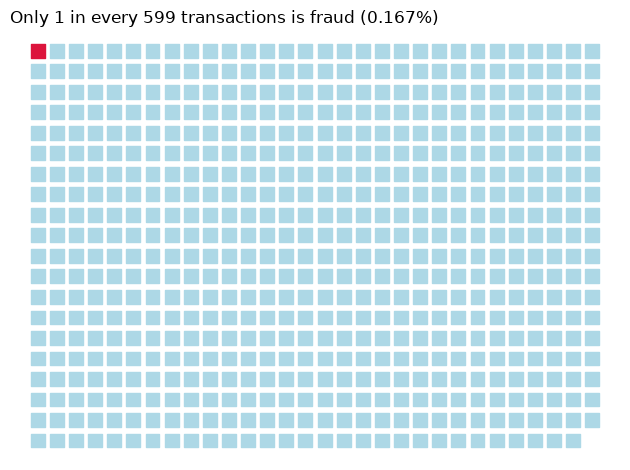

In [136]:
import matplotlib.pyplot as plt

fraud_percentage = balance.loc[balance["transaction_type"] == "Fraud", "percentage"].iloc[0]
number_of_squares = round(100 / fraud_percentage)
cols = 30

x = [i % cols for i in range(number_of_squares)]
y = [i // cols for i in range(number_of_squares)]
colors = ["crimson" if i == 0 else "lightblue" for i in range(number_of_squares)]

fig, ax = plt.subplots()
ax.scatter(x, y, c=colors, marker="s", s=100)
ax.invert_yaxis()
ax.axis("off")
ax.set_title(f"Only 1 in every {number_of_squares} transactions is fraud ({fraud_percentage}%)", loc="left")
plt.tight_layout()
plt.savefig("../images/class_balance.png", dpi=150)
plt.show()

### Transaction amounts
This section compares typical fraud and normal transaction amounts, then looks at which amount ranges carry the highest fraud rate.

In [140]:
q("""
SELECT
    CASE WHEN Class = 1 THEN 'Fraud' ELSE 'Normal' END AS transaction_type,
    ROUND(AVG(Amount), 2) AS average_amount,
    ROUND(MEDIAN(Amount), 2) AS median_amount,
    ROUND(MAX(Amount), 2) AS max_amount
FROM transactions
GROUP BY transaction_type
""")

,transaction_type,average_amount,median_amount,max_amount
0,Fraud,123.87,9.82,2125.87
1,Normal,88.41,22.00,25691.16


In [150]:
by_amount_range = q("""
SELECT
    CASE
        WHEN Amount = 0 THEN '0'
        WHEN Amount < 10 THEN '0-10'
        WHEN Amount < 50 THEN '10-50'
        WHEN Amount < 100 THEN '50-100'
        WHEN Amount < 500 THEN '100-500'
        ELSE '500+'
    END AS amount_range,
    COUNT(*) AS number_of_transactions,
    SUM(Class) AS number_of_fraud,
    ROUND(100.0 * SUM(Class) / COUNT(*), 3) AS fraud_rate
FROM transactions
GROUP BY amount_range
ORDER BY MIN(Amount)
""")
by_amount_range

,amount_range,number_of_transactions,number_of_fraud,fraud_rate
0,0,1808,25.0,1.383
1,0-10,95065,213.0,0.224
2,10-50,91937,54.0,0.059
3,50-100,37640,56.0,0.149
4,100-500,47817,91.0,0.190
5,500+,9459,34.0,0.359


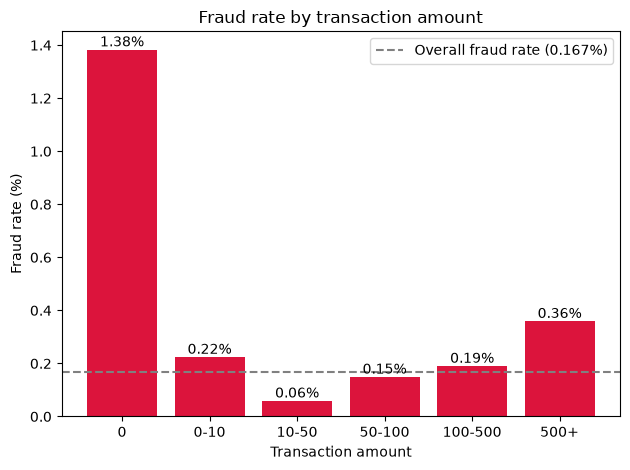

In [152]:
fig, ax = plt.subplots()
bars = ax.bar(by_amount_range["amount_range"], by_amount_range["fraud_rate"], color="crimson")
ax.bar_label(bars, fmt="%.2f%%")   #fraud rate on top of each bar
ax.axhline(fraud_percentage, linestyle="--", color="grey", label=f"Overall fraud rate ({fraud_percentage:.3f}%)")

ax.set_xlabel("Transaction amount")
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud rate by transaction amount", loc="center")
ax.legend()
plt.tight_layout()
plt.savefig("../images/fraud_rate_by_amount_range.png", dpi=150)
plt.show()

**Findings:**
- Most fraud is small: the median fraud is 9.82 vs 22.00 for normal transactions, possibly fraudsters testing stolen cards with small purchases.
- Rate ≠ volume: zero-amount transactions have the highest fraud rate (~8× average), but the 0–10 range holds the most fraud (45% of all cases).
- Large transactions are riskier: amounts over 500 are about 2× more likely to be fraud than average.
- Open question: 1,808 transactions are for exactly 0 (possibly card verification checks).

### Time patterns
Time counts seconds from the first transaction (about 48 hours of data),
so it's converted to an hour from 0 to 23. Hour 0 isn't necessarily midnight, since the dataset doesn't say when it starts.

In [154]:
by_hour = q("""
SELECT
    CAST(FLOOR(Time / 3600) AS INTEGER) % 24 AS hour,
    COUNT(*) AS number_of_transactions,
    CAST(SUM(Class) AS INTEGER) AS number_of_fraud,
    ROUND(100.0 * SUM(Class) / COUNT(*), 3) AS fraud_rate
FROM transactions
GROUP BY hour
ORDER BY hour
""")
by_hour


,hour,number_of_transactions,number_of_fraud,fraud_rate
0,0,7647,6,0.078
1,1,4208,10,0.238
2,2,3308,48,1.451
3,3,3487,17,0.488
4,4,2204,23,1.044
5,5,2988,11,0.368
6,6,4082,9,0.220
7,7,7233,23,0.318
8,8,10232,9,0.088
9,9,15767,16,0.101


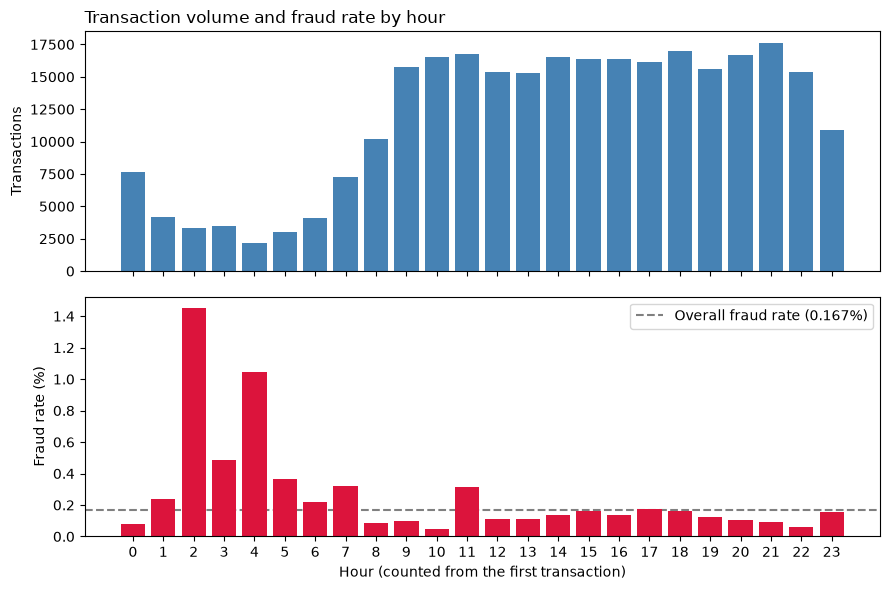

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

#Top: how many transactions happen each hour
ax1.bar(by_hour["hour"], by_hour["number_of_transactions"], color="steelblue")
ax1.set_ylabel("Transactions")
ax1.set_title("Transaction volume and fraud rate by hour", loc="left")

#Bottom: what share of them are fraud
ax2.bar(by_hour["hour"], by_hour["fraud_rate"], color="crimson", zorder=2)
ax2.axhline(fraud_percentage, linestyle="--", color="grey", zorder=1, label=f"Overall fraud rate ({fraud_percentage:.3f}%)")
ax2.set_ylabel("Fraud rate (%)")
ax2.set_xlabel("Hour (counted from the first transaction)")
ax2.set_xticks(range(24))
ax2.legend()

plt.tight_layout()
plt.savefig("../images/fraud_by_hour.png", dpi=150)
plt.show()

**Findings:**
- Hours 1–6 look like night-time: transaction volume drops to 2,200–4,200 per hour, compared with 15,000–17,000 during the day.
- Fraud is concentrated at night: these hours contain only 7% of all transactions but 25% of all fraud (118 of 473).
- Hour 11 is an exception: it has the most fraud of any hour (53 cases), possibly a single coordinated attack rather than a regular pattern.
- Caveat: the data covers only two days, so hourly patterns rest on small numbers and should be confirmed with more data.